In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)


file_path = r"D:\Sheeba\Coursework\bank-additional-full.csv"

df = pd.read_csv(file_path, sep=';')
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
print("Dataset dimensions:", df.shape)
print("\nData types and non-null counts:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include='all').T)

print("\nActual null values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nExact duplicate records:", df.duplicated().sum())

Dataset dimensions: (41188, 21)

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Actual null values:


Series([], dtype: int64)


Exact duplicate records: 12


,Count,Percentage
y,,
no,36548,88.73
yes,4640,11.27


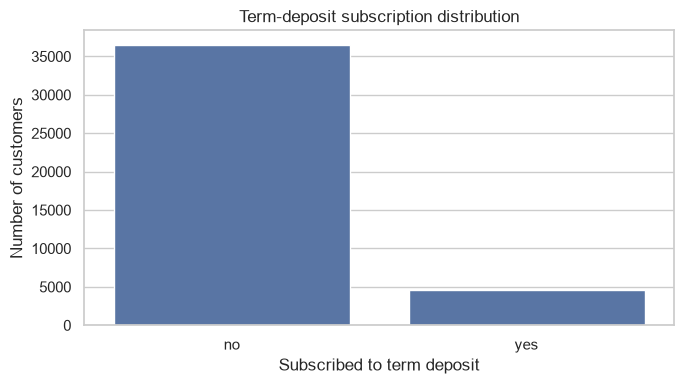

In [6]:
# Target distribution: counts and percentages
target_counts = df['y'].value_counts()
target_percentages = df['y'].value_counts(normalize=True).mul(100)

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages.round(2)
})
display(target_summary)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='y', order=['no', 'yes'])
plt.title('Term-deposit subscription distribution')
plt.xlabel('Subscribed to term deposit')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.show()

In [8]:
# Count the literal 'unknown' values in categorical columns.
categorical_original = df.select_dtypes(include=['object', 'str']).columns
unknown_summary = pd.DataFrame({
    'Unknown count': {col: (df[col] == 'unknown').sum()
                      for col in categorical_original}
})
unknown_summary = unknown_summary[unknown_summary['Unknown count'] > 0]
unknown_summary['Percentage of records'] = (
    unknown_summary['Unknown count'] / len(df) * 100
).round(2)
display(unknown_summary)

,Unknown count,Percentage of records
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40


In [9]:
# Work on a copy so that the original loaded DataFrame remains unchanged.
data = df.drop_duplicates().copy()

# Remove duration: it is only known after the call.
data = data.drop(columns=['duration'])

# Represent previous contact explicitly.
data['previously_contacted'] = (data['pdays'] != 999).astype(int)
data['pdays'] = data['pdays'].replace(999, np.nan)

# Separate predictors and target; encode target as 0=no and 1=yes.
X = data.drop(columns='y')
y = data['y'].map({'no': 0, 'yes': 1})

print("Prepared data shape:", data.shape)
print("Predictor shape:", X.shape)
print("Target distribution:")
display(y.value_counts().rename(index={0: 'no', 1: 'yes'}))

Prepared data shape: (41176, 21)
Predictor shape: (41176, 20)
Target distribution:


y
no     36537
yes     4639
Name: count, dtype: int64

In [11]:
# Stratified 80/20 split preserves the target proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Identify categorical columns (text/string variables)
categorical_cols = X.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

# Identify numerical columns (integer and floating-point variables)
numerical_cols = X.select_dtypes(
    include=['number']
).columns.tolist()

# Display the identified columns
print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

# Confirm that all predictor columns have been classified
print("\nTotal predictor columns:", X.shape[1])
print("Total classified columns:", len(categorical_cols) + len(numerical_cols))

# Logistic regression: median imputation + scaling for numeric variables;
# most-frequent imputation + one-hot encoding for categorical variables.
logistic_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numerical_cols),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
])

# Tree models do not require feature scaling.
tree_preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numerical_cols),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training subscriber rate:", round(y_train.mean() * 100, 2), "%")
print("Testing subscriber rate:", round(y_test.mean() * 100, 2), "%")

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Numerical columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Total predictor columns: 20
Total classified columns: 20
Training records: 32940
Testing records: 8236
Training subscriber rate: 11.27 %
Testing subscriber rate: 11.27 %


In [12]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Subscriber precision:", round(precision_score(y_test, baseline_pred, zero_division=0), 4))
print("Subscriber recall:", round(recall_score(y_test, baseline_pred, zero_division=0), 4))
print("Subscriber F1:", round(f1_score(y_test, baseline_pred, zero_division=0), 4))
print("\nConfusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_test, baseline_pred))

Baseline accuracy: 0.8873
Subscriber precision: 0.0
Subscriber recall: 0.0
Subscriber F1: 0.0

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[7308    0]
 [ 928    0]]


In [13]:
models = {
    'HistGradientBoosting': Pipeline([
        ('preprocess', tree_preprocessor),
        ('model', HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.08, max_leaf_nodes=20,
            l2_regularization=1.0, random_state=42
        ))
    ]),
    'Random Forest': Pipeline([
        ('preprocess', tree_preprocessor),
        ('model', RandomForestClassifier(
            n_estimators=250, min_samples_leaf=2,
            class_weight='balanced_subsample',
            n_jobs=-1, random_state=42
        ))
    ]),
    'Logistic Regression': Pipeline([
        ('preprocess', logistic_preprocessor),
        ('model', LogisticRegression(
            max_iter=1500, class_weight='balanced',
            solver='liblinear', random_state=42
        ))
    ])
}

model_probabilities = {}
rows = []

for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)
    model_probabilities[name] = probabilities

    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision (yes)': precision_score(y_test, predictions, zero_division=0),
        'Recall (yes)': recall_score(y_test, predictions, zero_division=0),
        'F1 (yes)': f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'PR-AUC / Average precision': average_precision_score(y_test, probabilities)
    })

comparison = pd.DataFrame(rows).set_index('Model').sort_values(
    'PR-AUC / Average precision', ascending=False
)
display(comparison.round(4))

,Accuracy,Precision (yes),Recall (yes),F1 (yes),ROC-AUC,PR-AUC / Average precision
Model,,,,,,
HistGradientBoosting,0.9015,0.6726,0.2457,0.3599,0.8144,0.4986
Random Forest,0.8876,0.5011,0.4892,0.4951,0.7983,0.4674
Logistic Regression,0.8304,0.3593,0.6455,0.4617,0.8001,0.4459


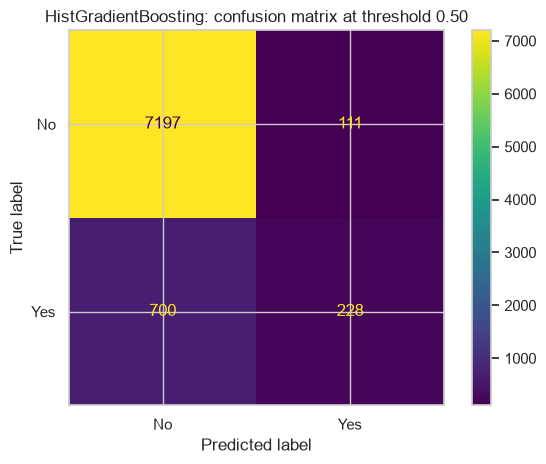

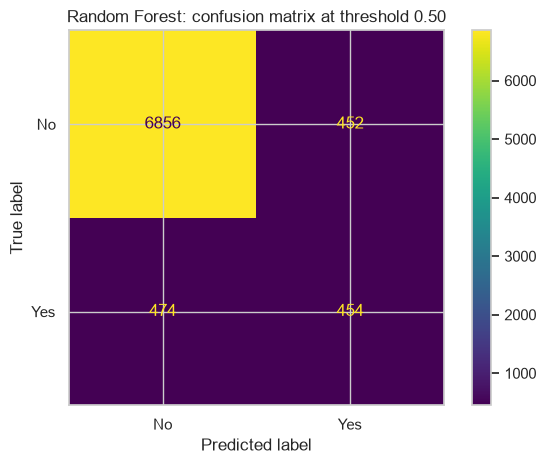

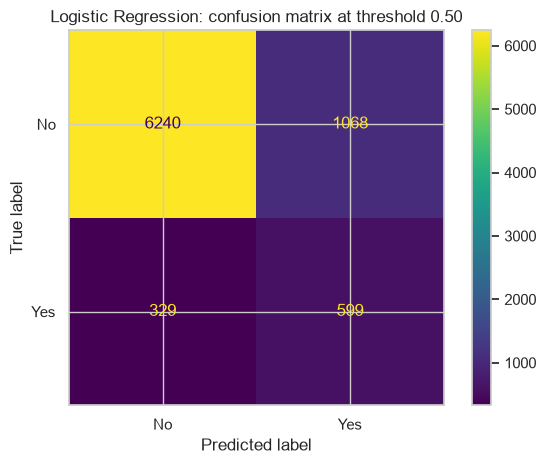

In [14]:
# Confusion matrices at the default 0.50 threshold.
for name, probabilities in model_probabilities.items():
    predictions = (probabilities >= 0.50).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=['No', 'Yes'], values_format='d'
    )
    plt.title(f'{name}: confusion matrix at threshold 0.50')
    plt.tight_layout()
    plt.show()

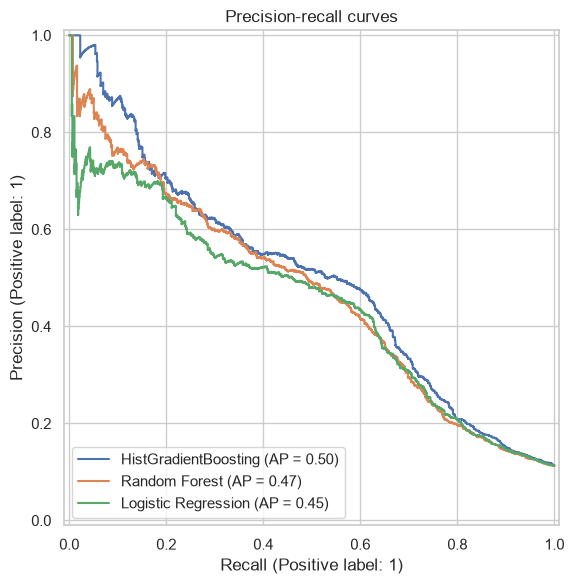

In [15]:
# Precision-recall curves are especially useful for an imbalanced target.
plt.figure(figsize=(8, 6))
for name, probabilities in model_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test, probabilities, name=name, ax=plt.gca()
    )
plt.title('Precision-recall curves')
plt.tight_layout()
plt.show()

In [16]:
# Choose the model with the highest test-set PR-AUC.
best_model_name = comparison.index[0]
best_probabilities = model_probabilities[best_model_name]
print("Leading model by test-set PR-AUC:", best_model_name)

threshold_rows = []
for threshold in [0.10, 0.15, 0.20, 0.2187, 0.25, 0.30, 0.40, 0.50, 0.60]:
    pred = (best_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'Customers selected': int(pred.sum()),
        'False positives (unnecessary calls)': int(fp),
        'False negatives (missed subscribers)': int(fn),
        'True positives (subscribers identified)': int(tp)
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

Leading model by test-set PR-AUC: HistGradientBoosting


,Threshold,Precision,Recall,F1,Customers selected,False positives (unnecessary calls),False negatives (missed subscribers),True positives (subscribers identified)
0,0.100,0.356,0.678,0.467,1765,1136,299,629
1,0.150,0.437,0.630,0.516,1338,753,343,585
2,0.200,0.469,0.607,0.529,1200,637,365,563
3,0.219,0.478,0.599,0.532,1163,607,372,556
4,0.250,0.487,0.582,0.530,1109,569,388,540
5,0.300,0.515,0.506,0.511,913,443,458,470
6,0.400,0.601,0.331,0.427,511,204,621,307
7,0.500,0.673,0.246,0.360,339,111,700,228
8,0.600,0.727,0.169,0.274,216,59,771,157


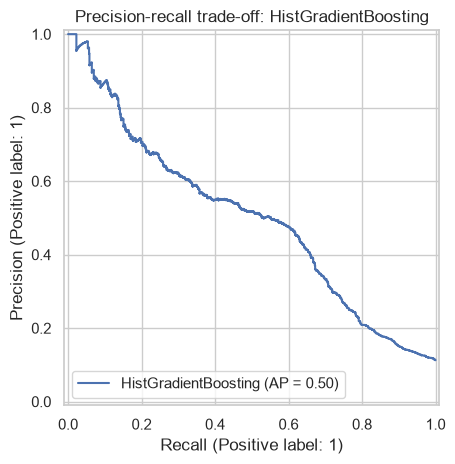

In [17]:
# Show precision and recall as the threshold changes.
precisions, recalls, thresholds = PrecisionRecallDisplay.from_predictions(
    y_test, best_probabilities, name=best_model_name
).precision, None, None
plt.title(f'Precision-recall trade-off: {best_model_name}')
plt.tight_layout()
plt.show()